<a href="https://colab.research.google.com/github/MarceloCoccaro12/Conjunto-Dados-DENATRAN2026/blob/main/denatran2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier
from scipy.stats import randint
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [ ]:
prf = pd.read_csv('/content/drive/MyDrive/arquivos/datatran2026.csv', sep=';', encoding='latin-1')

In [ ]:
prf

,id,data_inversa,dia_semana,horario,uf,br,km,municipio,causa_acidente,tipo_acidente,...,feridos_graves,ilesos,ignorados,feridos,veiculos,latitude,longitude,regional,delegacia,uop
0,742921.0,2026-01-01,quinta-feira,04:04:00,TO,153,155,ARAGUAINA,Objeto estático sobre o leito carroçável,Tombamento,...,0,1,3,0,5,"-7,291548","-48,286252",SPRF-TO,DEL02-TO,UOP01-DEL02-TO
1,742942.0,2026-01-01,quinta-feira,06:40:00,MG,262,"146,1",RIO CASCA,Condutor Dormindo,Colisão frontal,...,4,1,1,4,3,"-20,0240733","-42,7422291",SPRF-MG,DEL03-MG,UOP03-DEL03-MG
2,742943.0,2026-01-01,quinta-feira,06:58:00,SC,101,193,BIGUACU,Reação tardia ou ineficiente do condutor,Colisão lateral mesmo sentido,...,0,1,2,1,4,"-27,48935222","-48,65565777",SPRF-SC,DEL01-SC,UOP01-DEL01-SC
3,742947.0,2026-01-01,quinta-feira,07:05:00,DF,60,23,BRASILIA,Reação tardia ou ineficiente do condutor,Colisão traseira,...,0,1,1,1,3,"-15,988927","-48,2263",SPRF-DF,DEL03-DF,UOP01-DEL03-DF
4,742960.0,2026-01-01,quinta-feira,06:17:00,MT,163,1044,MATUPA,Transitar na contramão,Colisão frontal,...,1,1,3,1,5,"-10,14330603","-54,93075559",SPRF-MT,DEL06-MT,UOP03-DEL06-MT
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48707,800343.0,2026-08-18,terça-feira,01:00:00,RJ,40,16,TRES RIOS,Animais na Pista,Atropelamento de Animal,...,0,0,0,1,1,"-22,08456325","-43,17756621",SPRF-RJ,DEL05-RJ,UOP02-DEL05-RJ
48708,800421.0,2026-08-24,segunda-feira,08:20:00,MA,230,504,RIACHAO,Demais falhas mecânicas ou elétricas,Capotamento,...,0,1,0,2,1,"-7,410343","-46,853722",SPRF-MA,DEL05-MA,UOP01-DEL05-MA
48709,800432.0,2026-07-13,segunda-feira,10:00:00,MG,116,"414,6",GOVERNADOR VALADARES,Ultrapassagem Indevida,Colisão transversal,...,0,1,0,1,2,"-18,88603599","-41,94625676",SPRF-MG,DEL06-MG,UOP01-DEL06-MG
48710,800490.0,2026-08-29,sábado,18:30:00,RJ,101,486,ANGRA DOS REIS,Conversão proibida,Colisão transversal,...,1,0,1,1,2,"-22,96962","-44,298442",SPRF-RJ,DEL03-RJ,UOP03-DEL03-RJ


In [ ]:
prf.isnull().sum()

,0
id,0
data_inversa,0
dia_semana,0
horario,0
uf,0
br,0
km,0
municipio,0
causa_acidente,0
tipo_acidente,0


In [ ]:
prf_db = prf.dropna()
prf_db.isnull().sum()

,0
id,0
data_inversa,0
dia_semana,0
horario,0
uf,0
br,0
km,0
municipio,0
causa_acidente,0
tipo_acidente,0


In [ ]:
prf_db['classificacao_acidente'].unique()

array(['Com Vítimas Feridas', 'Sem Vítimas', 'Com Vítimas Fatais'],
      dtype=object)

In [ ]:
colunas_para_remover = [
    "id",
    "latitude",
    "longitude",
    "regional",
    "delegacia",
    "uop",
    "feridos_graves",
    "feridos_leves",
    "mortos",
    "ilesos",
    "ignorados",
    "feridos",
    "veiculos",
]

prf_filtrado = prf_db.drop(columns=colunas_para_remover)

In [ ]:
prf_filtrado

,data_inversa,dia_semana,horario,uf,br,km,municipio,causa_acidente,tipo_acidente,classificacao_acidente,fase_dia,sentido_via,condicao_metereologica,tipo_pista,tracado_via,uso_solo,pessoas
1,2026-01-01,quinta-feira,06:40:00,MG,262,"146,1",RIO CASCA,Condutor Dormindo,Colisão frontal,Com Vítimas Feridas,Pleno dia,Crescente,Céu Claro,Simples,Reta,Não,6
2,2026-01-01,quinta-feira,06:58:00,SC,101,193,BIGUACU,Reação tardia ou ineficiente do condutor,Colisão lateral mesmo sentido,Com Vítimas Feridas,Amanhecer,Crescente,Nublado,Dupla,Curva,Sim,3
3,2026-01-01,quinta-feira,07:05:00,DF,60,23,BRASILIA,Reação tardia ou ineficiente do condutor,Colisão traseira,Com Vítimas Feridas,Pleno dia,Decrescente,Céu Claro,Dupla,Aclive;Reta,Não,3
4,2026-01-01,quinta-feira,06:17:00,MT,163,1044,MATUPA,Transitar na contramão,Colisão frontal,Com Vítimas Feridas,Amanhecer,Decrescente,Sol,Simples,Reta,Não,3
5,2026-01-01,quinta-feira,08:50:00,SP,116,568,BARRA DO TURVO,Velocidade Incompatível,Colisão com objeto,Com Vítimas Feridas,Pleno dia,Decrescente,Céu Claro,Dupla,Declive;Curva,Não,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48707,2026-08-18,terça-feira,01:00:00,RJ,40,16,TRES RIOS,Animais na Pista,Atropelamento de Animal,Com Vítimas Feridas,Plena Noite,Decrescente,Céu Claro,Dupla,Reta,Não,1
48708,2026-08-24,segunda-feira,08:20:00,MA,230,504,RIACHAO,Demais falhas mecânicas ou elétricas,Capotamento,Com Vítimas Feridas,Pleno dia,Crescente,Céu Claro,Simples,Curva;Declive,Não,3
48709,2026-07-13,segunda-feira,10:00:00,MG,116,"414,6",GOVERNADOR VALADARES,Ultrapassagem Indevida,Colisão transversal,Com Vítimas Feridas,Pleno dia,Decrescente,Sol,Simples,Reta;Retorno Regulamentado,Sim,2
48710,2026-08-29,sábado,18:30:00,RJ,101,486,ANGRA DOS REIS,Conversão proibida,Colisão transversal,Com Vítimas Feridas,Plena Noite,Decrescente,Céu Claro,Simples,Reta,Sim,2


In [ ]:
prf_filtrado.describe()

,br,pessoas
count,48685.000000,48685.000000
mean,210.816247,2.632063
std,129.028211,2.283247
min,0.000000,1.000000
25%,101.000000,2.000000
50%,163.000000,2.000000
75%,324.000000,3.000000
max,495.000000,88.000000


In [ ]:
prf_filtrado.info()

<class 'pandas.core.frame.DataFrame'>
Index: 48685 entries, 1 to 48711
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   data_inversa            48685 non-null  object
 1   dia_semana              48685 non-null  object
 2   horario                 48685 non-null  object
 3   uf                      48685 non-null  object
 4   br                      48685 non-null  int64 
 5   km                      48685 non-null  object
 6   municipio               48685 non-null  object
 7   causa_acidente          48685 non-null  object
 8   tipo_acidente           48685 non-null  object
 9   classificacao_acidente  48685 non-null  object
 10  fase_dia                48685 non-null  object
 11  sentido_via             48685 non-null  object
 12  condicao_metereologica  48685 non-null  object
 13  tipo_pista              48685 non-null  object
 14  tracado_via             48685 non-null  object
 15  uso_sol

In [ ]:
prf_filtrado['classificacao_acidente'].value_counts()

,count
classificacao_acidente,
Com Vítimas Feridas,37658
Sem Vítimas,7537
Com Vítimas Fatais,3490


In [ ]:
X = prf_filtrado.drop('classificacao_acidente', axis=1)
y = prf_filtrado['classificacao_acidente']

In [ ]:
numerical_features = ['br', 'pessoas']
categorical_features = ['data_inversa',	'dia_semana',	'horario',	'uf',	'km',	'municipio',	'causa_acidente',	'tipo_acidente', 'fase_dia',	'sentido_via',	'condicao_metereologica',	'tipo_pista',	'tracado_via',	'uso_solo']

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[('num', StandardScaler(), numerical_features),
                  ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)]
)

In [ ]:
model_pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                                 ('classifier', RandomForestClassifier(random_state=42))])

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
model_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['br', 'pessoas']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['data_inversa', 'dia_semana',
                                                   'horario', 'uf', 'km',
                                                   'municipio',
                                                   'causa_acidente',
                                                   'tipo_acidente', 'fase_dia',
                                                   'sentido_via',
                                                   'condicao_metereologica',
                                                   'tipo_pista', 'tracado_via',
                                                   'uso_solo'])])),
                ('classifier', RandomForestClassifier(random_state=42))])

In [ ]:
y_pred = model_pipeline.predict(X_test)

In [ ]:
acuracia = accuracy_score(y_test, y_pred)
print(f'Acurácia: {acuracia * 100:.2f}%')

Acurácia: 79.74%


# Matriz de Confusão

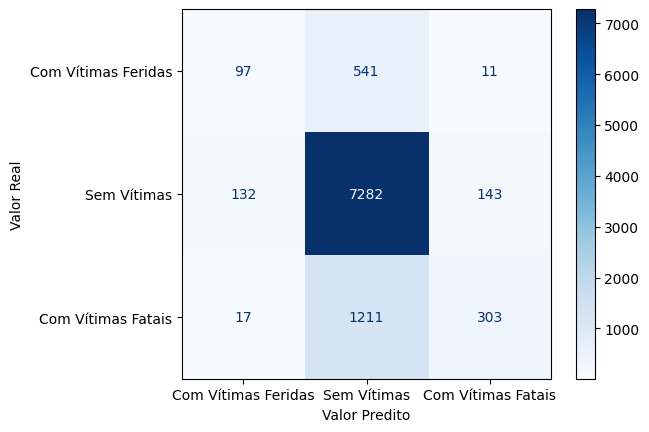

In [ ]:
classes = ['Com Vítimas Feridas', 'Sem Vítimas', 'Com Vítimas Fatais']

cm = confusion_matrix(y_test, y_pred)
matrix = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
matrix.plot(cmap=plt.cm.Blues)

plt.xlabel('Valor Predito')
plt.ylabel('Valor Real')
plt.show()

In [ ]:
param_dist = {
    'classifier__n_estimators':randint(50,200),
    'classifier__max_depth': [None, 5, 10]
}

random_search = RandomizedSearchCV(
    estimator=model_pipeline,
    param_distributions=param_dist,
    scoring='accuracy',
    cv=5,
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train)

best_param = random_search.best_params_
best_score = random_search.best_score_


print(f'Melhores parâmetros a ser utilizados: {best_param}')
print(f'Melhor Acurácia Media (Validação Cruzada): {best_score * 100:.2f}%')

Melhores parâmetros a ser utilizados: {'classifier__max_depth': None, 'classifier__n_estimators': 70}
Melhor Acurácia Media (Validação Cruzada): 79.75%


In [ ]:
best_model = random_search.best_estimator_
y_pred_tuned = best_model.predict(X_test)
acuracia_test = accuracy_score(y_test, y_pred_tuned)
print(f'Acurácia do conjunto de teste: {acuracia_test * 100:.2f}%')

Acurácia do conjunto de teste: 79.69%


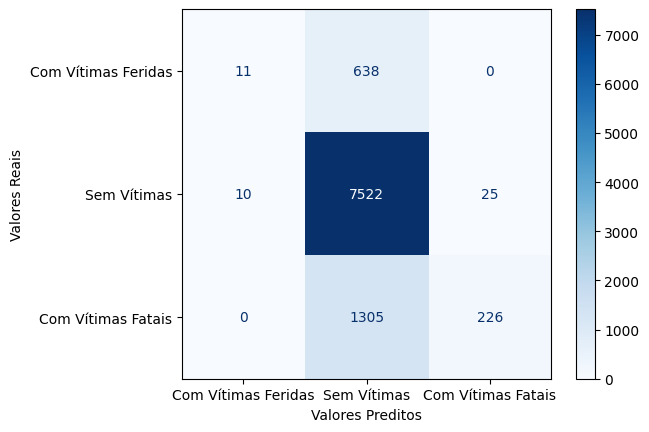

In [ ]:
classes = ['Com Vítimas Feridas', 'Sem Vítimas', 'Com Vítimas Fatais']

cm = confusion_matrix(y_test, y_pred_tuned)
matrix = ConfusionMatrixDisplay(cm, display_labels=classes)
matrix.plot(cmap=plt.cm.Blues)
plt.xlabel('Valores Preditos')
plt.ylabel('Valores Reais')
plt.show()